# Rank diagram for tscbench_runs

Loads test results with tsml_eval and plots a critical difference diagram of accuracy.

In [4]:
from pathlib import Path

import pandas as pd
from tsml_eval.evaluation.storage import load_classifier_results
from tsml_eval.evaluation.multiple_estimator_evaluation import plot_critical_difference

RUNS = Path("../tscbench_runs")

In [ ]:
rows = []
for f in RUNS.glob("*/Predictions/*/testResample*.csv"):
    r = load_classifier_results(str(f))
    rows.append({"model": f.parts[-4], "dataset": f.parts[-2], "resample": r.resample_id,
                 "accuracy": r.accuracy, "log_loss": r.log_loss})
df = pd.DataFrame(rows)

acc = df.groupby(["dataset", "model"])["accuracy"].mean().unstack()
acc

dropped datasets: ['BME', 'CBF', 'Coffee', 'Rock', 'ShapeletSim']
datasets used: 15


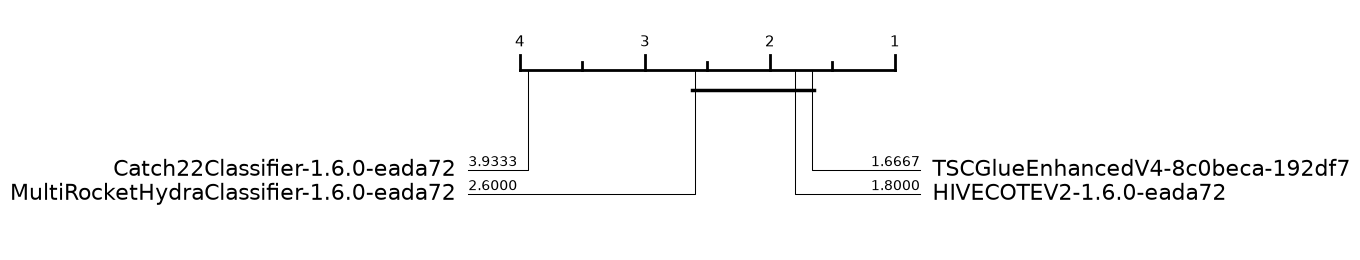

In [6]:
complete = acc.dropna()  # datasets every model has finished
print("dropped datasets:", sorted(set(acc.index) - set(complete.index)))
print("datasets used:", len(complete))

fig, ax = plot_critical_difference(complete.to_numpy(), list(complete.columns))

In [ ]:
ll = df.groupby(["dataset", "model"])["log_loss"].mean().unstack().dropna()
print("datasets used:", len(ll))

fig, ax = plot_critical_difference(ll.to_numpy(), list(ll.columns), lower_better=True)